# Notebook base — exploração e tratamento dos dados
Este é o ponto de partida comum para os próximos modelos da competição Home Credit.

**Parte 1:** carregar, conhecer e explorar os dados.  
**Parte 2:** decidir e aplicar o tratamento a partir do que foi observado.  
**Parte 3:** salvar a base limpa e uma divisão preparada que poderá ser usada pelos mesmos pares de modelos.

Cada célula faz uma etapa curta. Leia a saída e a explicação antes de continuar. As bases originais ficam intactas durante toda a exploração.

## Parte 1 — Conhecer e explorar
### 1. Importar as bibliotecas e os dados
Vamos começar com pandas para tabelas, numpy para valores ausentes e matplotlib para gráficos. O caminho abaixo funciona quando este notebook está na pasta GCI, ao lado de input.

No Colab, monte seu Drive e use o caminho real da pasta Competition em `pasta`. Execute a preparação de ambiente antes da leitura dos CSVs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pasta = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "input" / "train.csv").exists()), Path("/content/drive/MyDrive/Competition"))  # No Colab, ajuste o caminho se necessario.
treino = pd.read_csv(pasta / "input" / "train.csv")
teste = pd.read_csv(pasta / "input" / "test.csv")

### 2. Ver a descrição dos dados com describe()
A contagem (count) mostra quantos valores estão preenchidos. mean é a média e std é o desvio padrão. min e max mostram os extremos. 25%, 50% e 75% são os quartis; 50% é a mediana.

Vamos olhar primeiro o treino e depois o teste. Ainda não estamos corrigindo nada.

In [2]:
treino.describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,171202.0,85600.500000,49421.904730,0.000000e+00,42800.250000,85600.500000,128400.750000,1.712010e+05
CNT_CHILDREN,171202.0,0.416490,0.720138,0.000000e+00,0.000000,0.000000,1.000000,1.400000e+01
AMT_INCOME_TOTAL,171202.0,168371.213673,107234.793540,2.610000e+04,112500.000000,146250.000000,202500.000000,1.350000e+07
AMT_CREDIT,171202.0,599129.309526,402816.996913,4.500000e+04,270000.000000,514602.000000,808650.000000,4.050000e+06
AMT_ANNUITY,171202.0,27120.065953,14450.252689,1.980000e+03,16546.500000,24916.500000,34600.500000,1.709865e+05
AMT_GOODS_PRICE,171202.0,538056.896715,368572.734241,4.500000e+04,238500.000000,450000.000000,679500.000000,2.254500e+06
REGION_POPULATION_RELATIVE,171202.0,0.020839,0.013803,2.900000e-04,0.010006,0.018850,0.028663,7.250800e-02
DAYS_BIRTH,171202.0,-16045.340504,4363.792228,-2.522900e+04,-19686.000000,-15778.000000,-12420.000000,-7.673000e+03
DAYS_EMPLOYED,171202.0,63960.411969,141401.513149,-1.791200e+04,-2772.000000,-1215.000000,-288.000000,3.652430e+05
DAYS_REGISTRATION,171202.0,-4994.982524,3525.760241,-2.467200e+04,-7490.000000,-4515.000000,-2008.000000,0.000000e+00


In [3]:
teste.describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,61500.0,201951.500000,17753.665115,171202.000000,186576.750000,201951.500000,217326.250000,2.327010e+05
CNT_CHILDREN,61500.0,0.421171,0.732735,0.000000,0.000000,0.000000,1.000000,1.900000e+01
AMT_INCOME_TOTAL,61500.0,169549.418410,486278.144693,25650.000000,112500.000000,144000.000000,202500.000000,1.170000e+08
AMT_CREDIT,61500.0,595668.164488,398563.418492,45000.000000,270000.000000,509400.000000,808650.000000,3.860019e+06
AMT_ANNUITY,61500.0,27028.553317,14168.393666,2164.500000,16618.500000,24849.000000,34573.500000,1.709865e+05
AMT_GOODS_PRICE,61500.0,533671.431392,364560.407886,40500.000000,238500.000000,450000.000000,679500.000000,2.254500e+06
REGION_POPULATION_RELATIVE,61500.0,0.020780,0.013790,0.000533,0.010006,0.018850,0.028663,7.250800e-02
DAYS_BIRTH,61500.0,-15915.226016,4359.964540,-25201.000000,-19539.000000,-15586.500000,-12290.000000,-7.678000e+03
DAYS_EMPLOYED,61500.0,60829.342553,138657.773191,-16852.000000,-2687.000000,-1185.000000,-300.000000,3.652430e+05
DAYS_REGISTRATION,61500.0,-4945.935935,3496.555151,-22442.000000,-7408.250000,-4458.000000,-2018.000000,0.000000e+00


**O que observar:** uma média muito distante da mediana pode indicar assimetria. Um máximo muito alto merece investigação. Uma contagem menor que o total de linhas indica ausência. O máximo 365243 de DAYS_EMPLOYED chama atenção porque a variável representa dias de emprego.

### 3. Ver os tipos e preenchimento com info()
Agora conferimos o nome, o tipo e a quantidade de valores preenchidos em cada coluna. Valores em texto precisarão de preparação antes de entrar em vários modelos.

In [4]:
treino.info()

<class 'pandas.DataFrame'>
RangeIndex: 171202 entries, 0 to 171201
Data columns (total 34 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   SK_ID_CURR                  171202 non-null  int64  
 1   NAME_CONTRACT_TYPE          171202 non-null  str    
 2   CODE_GENDER                 171202 non-null  str    
 3   CNT_CHILDREN                171202 non-null  int64  
 4   AMT_INCOME_TOTAL            171202 non-null  float64
 5   AMT_CREDIT                  171202 non-null  float64
 6   AMT_ANNUITY                 171202 non-null  float64
 7   AMT_GOODS_PRICE             171202 non-null  float64
 8   NAME_INCOME_TYPE            171202 non-null  str    
 9   NAME_EDUCATION_TYPE         171202 non-null  str    
 10  NAME_FAMILY_STATUS          171202 non-null  str    
 11  NAME_HOUSING_TYPE           171202 non-null  str    
 12  REGION_POPULATION_RELATIVE  171202 non-null  float64
 13  DAYS_BIRTH               

In [5]:
teste.info()

<class 'pandas.DataFrame'>
RangeIndex: 61500 entries, 0 to 61499
Data columns (total 33 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   SK_ID_CURR                  61500 non-null  int64  
 1   NAME_CONTRACT_TYPE          61500 non-null  str    
 2   CODE_GENDER                 61500 non-null  str    
 3   CNT_CHILDREN                61500 non-null  int64  
 4   AMT_INCOME_TOTAL            61500 non-null  float64
 5   AMT_CREDIT                  61500 non-null  float64
 6   AMT_ANNUITY                 61500 non-null  float64
 7   AMT_GOODS_PRICE             61500 non-null  float64
 8   NAME_INCOME_TYPE            61500 non-null  str    
 9   NAME_EDUCATION_TYPE         61500 non-null  str    
 10  NAME_FAMILY_STATUS          61500 non-null  str    
 11  NAME_HOUSING_TYPE           61500 non-null  str    
 12  REGION_POPULATION_RELATIVE  61500 non-null  float64
 13  DAYS_BIRTH                  61500 non-null

### 4. Ver as primeiras linhas com head()
A descrição é um resumo. head() ajuda a enxergar como uma linha real está organizada.

In [6]:
treino.head()

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,Married,House / apartment,0.010032,-9233,-878,-333.0,-522,NaN,1,1,1,Core staff,2.0,2,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,Married,House / apartment,0.008019,-20148,365243,-4469.0,-3436,NaN,1,0,0,Other,2.0,2,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,Married,House / apartment,0.004960,-18496,-523,-3640.0,-2050,NaN,1,1,1,Core staff,2.0,2,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0
3,3,Cash loans,F,0,67500.0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,Widow,House / apartment,0.005002,-24177,365243,-4950.0,-3951,NaN,1,0,0,Other,1.0,3,XNA,NaN,0.105235,0.767523,0.0,0.0,0.0,0.0,0.0,0
4,4,Cash loans,M,0,157500.0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,Married,With parents,0.006296,-10685,-697,-5101.0,-3226,NaN,1,1,1,Drivers,2.0,3,Business Entity Type 3,0.342344,0.202490,0.669057,-1243.0,0.0,0.0,0.0,4.0,1


In [7]:
teste.head()

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,171202,Cash loans,F,1,144000.0,961146.0,28233.0,688500.0,Working,Higher education,Married,House / apartment,0.025164,-12108,-2372,-2446.0,-3022,NaN,1,1,0,Medicine staff,3.0,2,Kindergarten,NaN,0.720416,NaN,-1.0,NaN,NaN,NaN,NaN
1,171203,Cash loans,F,0,103500.0,296280.0,16069.5,225000.0,Working,Secondary / secondary special,Married,House / apartment,0.007020,-17907,-1712,-10450.0,-253,NaN,1,1,1,Cleaning staff,2.0,2,School,NaN,0.287306,NaN,-212.0,NaN,NaN,NaN,NaN
2,171204,Cash loans,F,1,180000.0,183694.5,11236.5,139500.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,0.006852,-15221,-553,-1056.0,-4495,NaN,1,1,0,Other,2.0,3,Trade: type 7,NaN,0.352456,0.389339,-428.0,0.0,1.0,1.0,1.0
3,171205,Revolving loans,F,2,225000.0,450000.0,22500.0,450000.0,Working,Higher education,Married,House / apartment,0.035792,-11217,-1438,-6096.0,-1189,NaN,1,1,0,Other,4.0,2,Business Entity Type 3,NaN,0.470384,0.217629,-442.0,0.0,0.0,0.0,3.0
4,171206,Cash loans,F,2,144000.0,545040.0,26640.0,450000.0,Working,Higher education,Married,House / apartment,0.020713,-11415,-2362,-3257.0,-1728,14.0,1,1,0,Other,4.0,3,Business Entity Type 3,0.269931,0.373133,NaN,-1333.0,0.0,0.0,0.0,3.0


### 5. Entender o que existe nas bases
Cada linha representa um pedido de crédito. SK_ID_CURR é o identificador. TARGET é o que queremos prever: 1 representa dificuldades de pagamento e 0 os demais casos. O teste não possui TARGET.

As demais colunas descrevem contrato, características pessoais/familiares, renda, crédito, trabalho, região, scores e consultas ao bureau. O dicionário do curso detalha o significado de cada coluna. Não temos datas de observação que permitam interpretar os IDs como uma sequência temporal.

In [8]:
print("Treino:", treino.shape)
print("Teste:", teste.shape)
print("Colunas só no treino:", treino.columns.difference(teste.columns).tolist())
print("Colunas só no teste:", teste.columns.difference(treino.columns).tolist())

Treino: (171202, 34)
Teste: (61500, 33)
Colunas só no treino: ['TARGET']
Colunas só no teste: []


In [9]:
treino.columns.tolist()

['SK_ID_CURR', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'ORGANIZATION_TYPE', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'DAYS_LAST_PHONE_CHANGE', 'AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR', 'TARGET']

### 6. Separar os nomes das variáveis numéricas e categóricas
Retiramos ID e TARGET desta lista de entradas. Estamos separando apenas os nomes das colunas; os dados continuam originais.

In [10]:
entradas = treino.drop(columns=["SK_ID_CURR", "TARGET"])
numericas = entradas.select_dtypes(include="number").columns.tolist()
categoricas = entradas.select_dtypes(exclude="number").columns.tolist()

print("Numéricas:", numericas)
print("Categóricas:", categoricas)

Numéricas: ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'DAYS_LAST_PHONE_CHANGE', 'AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR']
Categóricas: ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE']


### 7. Procurar outliers numéricos com boxplots
O boxplot resume os quartis e mostra pontos afastados do centro da distribuição. Cada coluna tem sua própria escala.

Um ponto fora dos limites não é automaticamente um erro. Flags de 0/1 e contagens raras também podem aparecer como atípicas. Vamos primeiro localizar os valores e entender seu significado.

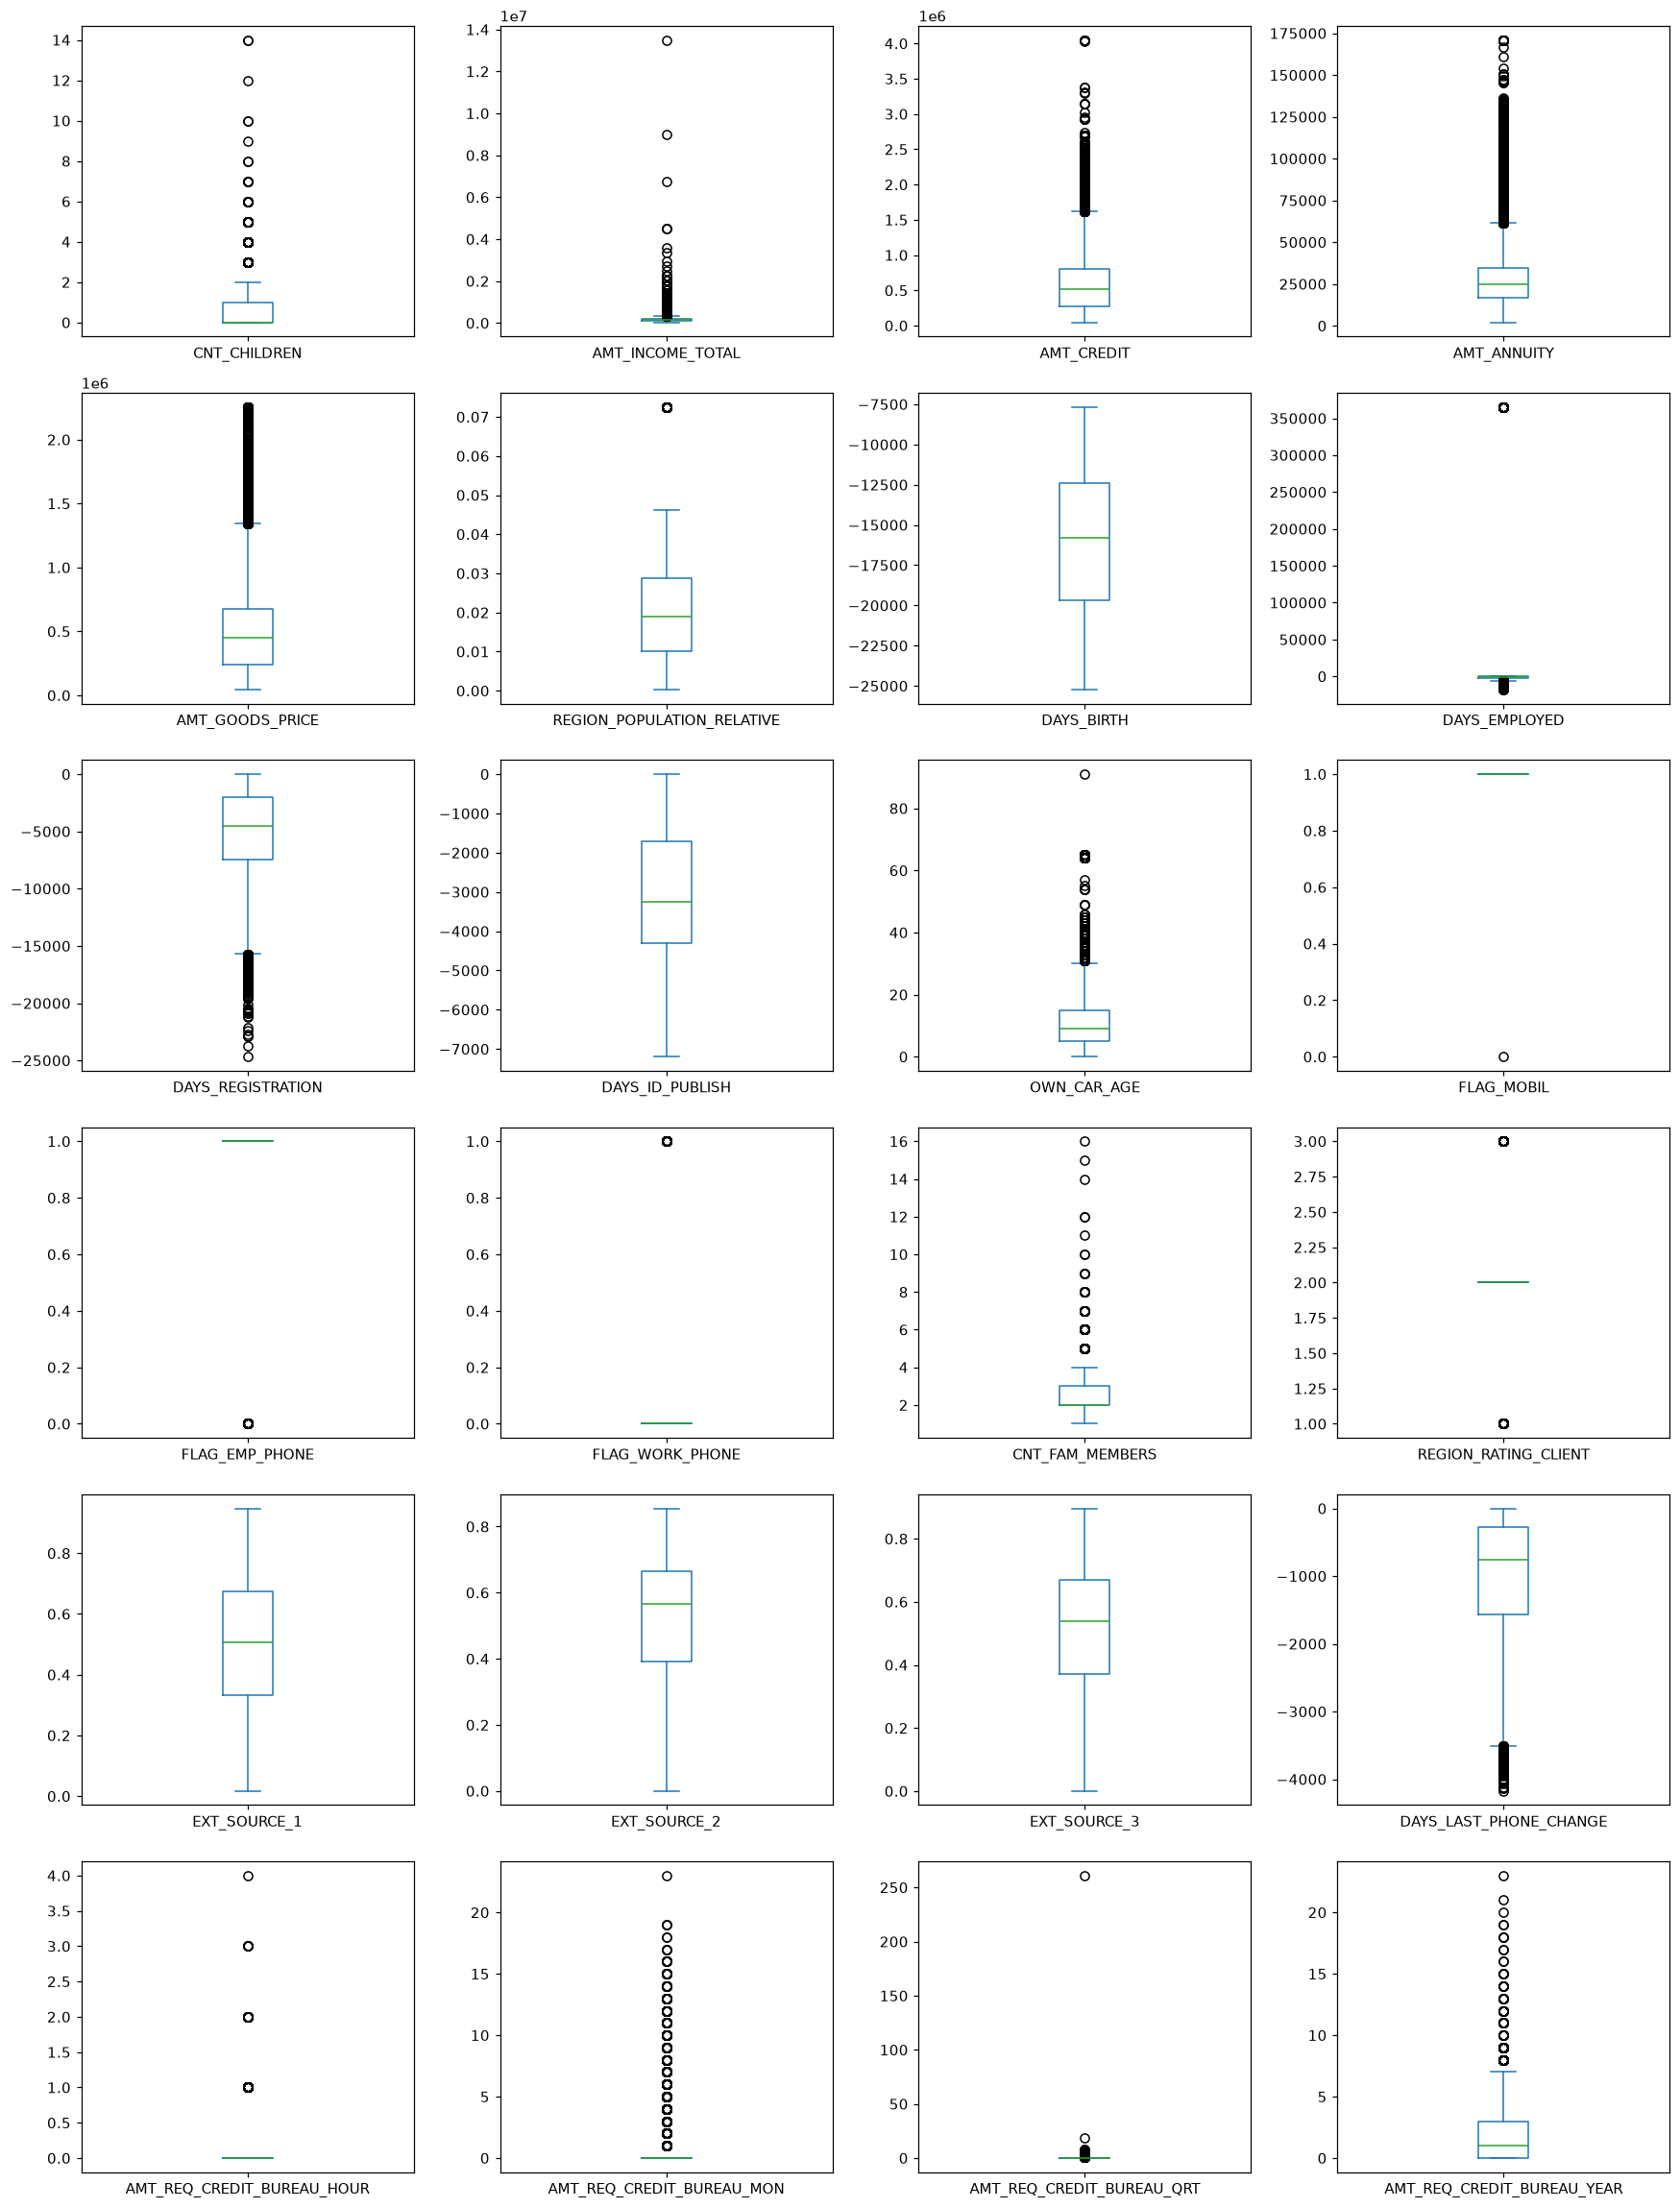

In [11]:
treino[numericas].plot(
    kind="box", subplots=True, layout=(6, 4),
    figsize=(16, 21), sharey=False
)
plt.tight_layout()
plt.show()

Vamos usar o IQR como mais uma forma de localizar extremos. IQR é Q3 − Q1. Os limites usuais são Q1 − 1,5 × IQR e Q3 + 1,5 × IQR. A tabela conta os pontos sinalizados sem excluir linhas.

In [12]:
q1 = treino[numericas].quantile(0.25)
q3 = treino[numericas].quantile(0.75)
iqr = q3 - q1

abaixo = treino[numericas].lt(q1 - 1.5 * iqr, axis="columns")
acima = treino[numericas].gt(q3 + 1.5 * iqr, axis="columns")
outliers = abaixo | acima

resumo_outliers = pd.DataFrame({
    "Q1": q1,
    "Q3": q3,
    "IQR": iqr,
    "quantidade_sinalizada": outliers.sum()
})
resumo_outliers.sort_values("quantidade_sinalizada", ascending=False)

,Q1,Q3,IQR,quantidade_sinalizada
REGION_RATING_CLIENT,2.000000,2.000000,0.000000,44800
DAYS_EMPLOYED,-2772.000000,-288.000000,2484.000000,40224
FLAG_WORK_PHONE,0.000000,0.000000,0.000000,34193
FLAG_EMP_PHONE,1.000000,1.000000,0.000000,30903
AMT_REQ_CREDIT_BUREAU_QRT,0.000000,0.000000,0.000000,28273
AMT_REQ_CREDIT_BUREAU_MON,0.000000,0.000000,0.000000,24353
AMT_GOODS_PRICE,238500.000000,679500.000000,441000.000000,8197
AMT_INCOME_TOTAL,112500.000000,202500.000000,90000.000000,7784
REGION_POPULATION_RELATIVE,0.010006,0.028663,0.018657,4624
AMT_ANNUITY,16546.500000,34600.500000,18054.000000,4179


**Como analisar essa tabela:** se o IQR for zero, valores raros podem ser sinalizados mesmo sendo válidos. Para renda e crédito, devemos investigar a cauda. Para dias de emprego, devemos procurar uma sentinela. As decisões serão tomadas na Parte 2.

#### Investigar a renda
Compare os quantis com o máximo. Depois veja os maiores valores de cada base. Eles aparecem na exploração, mas permanecem nos dados.

In [13]:
treino["AMT_INCOME_TOTAL"].describe(percentiles=[0.50, 0.90, 0.99, 0.999])

count    1.712020e+05
mean     1.683712e+05
std      1.072348e+05
min      2.610000e+04
50%      1.462500e+05
90%      2.700000e+05
99%      4.635000e+05
99.9%    9.000000e+05
max      1.350000e+07
Name: AMT_INCOME_TOTAL, dtype: float64

In [14]:
treino[["SK_ID_CURR", "AMT_INCOME_TOTAL"]].nlargest(5, "AMT_INCOME_TOTAL")

,SK_ID_CURR,AMT_INCOME_TOTAL
113305,113305,13500000.0
159447,159447,9000000.0
9689,9689,6750000.0
56146,56146,4500000.0
66762,66762,4500000.0


In [15]:
teste[["SK_ID_CURR", "AMT_INCOME_TOTAL"]].nlargest(5, "AMT_INCOME_TOTAL")

,SK_ID_CURR,AMT_INCOME_TOTAL
16579,187781,117000000.0
50303,221505,18000090.0
13452,184654,3825000.0
26818,198020,3375000.0
23705,194907,3150000.0


Uma escala logarítmica ajuda a enxergar a distribuição quando há valores muito altos. Aqui transformamos apenas a série usada no gráfico.

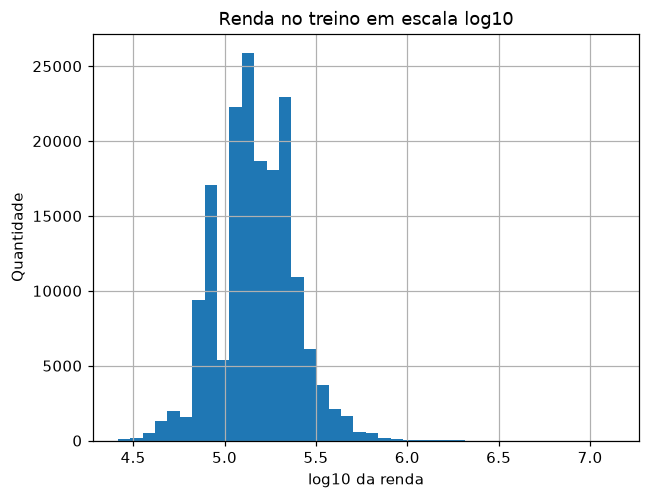

In [16]:
np.log10(treino["AMT_INCOME_TOTAL"]).hist(bins=40)
plt.title("Renda no treino em escala log10")
plt.xlabel("log10 da renda")
plt.ylabel("Quantidade")
plt.show()

**Leitura dos dados:** o treino tem renda máxima de 13,5 milhões e o teste de 117 milhões. Sem uma confirmação da fonte, não sabemos se são erros. Vamos mantê-los e registrar essa limitação. Um corte de extremos pode ser experimentado depois, com limites aprendidos apenas no treino de cada validação.

#### Investigar dias de emprego e idade do carro
O dicionário descreve DAYS_EMPLOYED como o tempo anterior ao pedido em que o emprego começou. Por isso, valores negativos são esperados. O valor 365243 equivale a aproximadamente mil anos: ele não pode ser interpretado literalmente como tempo de emprego.

In [17]:
treino["DAYS_EMPLOYED"].value_counts().head(10)

DAYS_EMPLOYED
 365243    30898
-200         106
-224          90
-384          85
-230          84
-201          83
-205          83
-216          82
-199          82
-231          80
Name: count, dtype: int64

In [18]:
print("Sentinela no treino:", treino["DAYS_EMPLOYED"].eq(365243).sum())
print("Sentinela no teste:", teste["DAYS_EMPLOYED"].eq(365243).sum())

treino.loc[
    treino["DAYS_EMPLOYED"].eq(365243),
    ["NAME_INCOME_TYPE", "ORGANIZATION_TYPE"]
].value_counts().head(10)

Sentinela no treino: 30898
Sentinela no teste: 10565


NAME_INCOME_TYPE  ORGANIZATION_TYPE
Pensioner         XNA                  30888
Unemployed        XNA                     10
Name: count, dtype: int64

In [19]:
treino["OWN_CAR_AGE"].value_counts().sort_index().tail(15)

OWN_CAR_AGE
39.0      46
40.0      57
41.0      41
42.0      22
43.0       9
44.0      11
45.0       5
46.0       3
49.0       4
54.0       5
55.0       1
57.0       1
64.0    1331
65.0     494
91.0       1
Name: count, dtype: int64

**Decisões para depois:** converter a sentinela de emprego em ausência. O tutorial do curso também propõe tratar idade de carro a partir de 60 anos como ausência; essa é uma hipótese do tutorial, não um erro comprovado. Vamos mantê-la explícita e guardar os originais para poder comparar outra versão.

### 8. Fazer a primeira matriz de correlação
A correlação de Pearson varia de −1 a 1 e descreve relações lineares. Não incluímos o ID, pois ele é um identificador. Incluímos TARGET para uma primeira leitura das associações.

Esta matriz ainda usa dados brutos. A sentinela de emprego pode distorcer correlações. Correlação não significa causa.

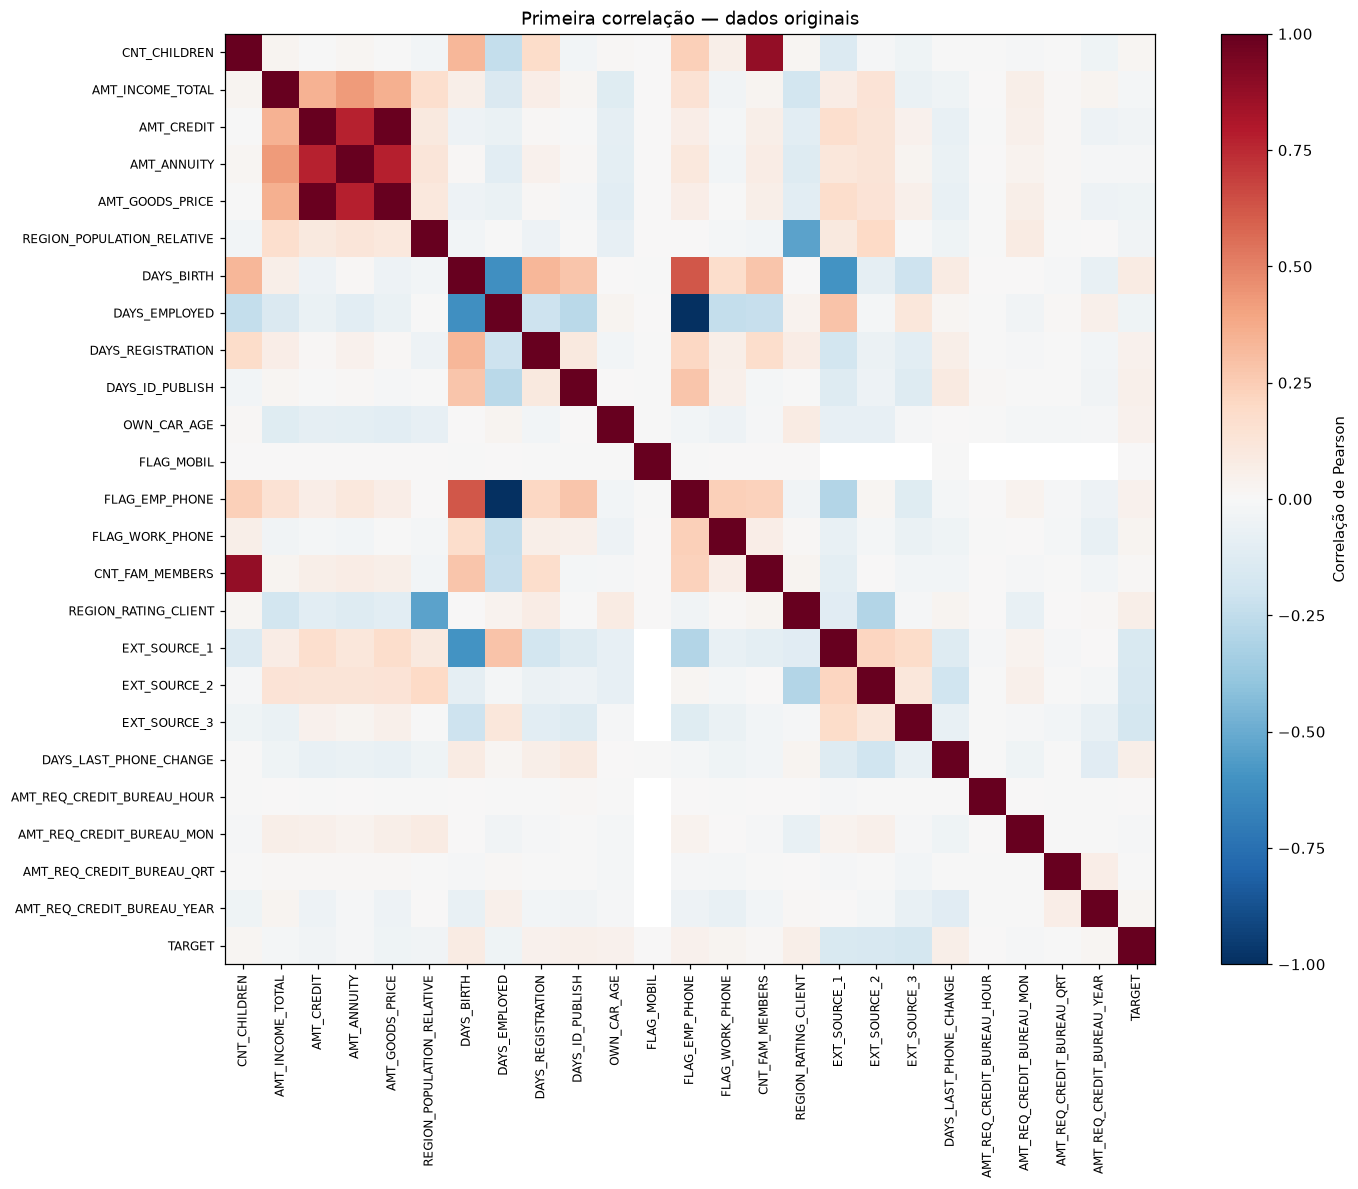

In [20]:
correlacao = treino.drop(columns="SK_ID_CURR").corr(numeric_only=True)

plt.figure(figsize=(14, 11))
plt.imshow(correlacao, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(correlacao)), correlacao.columns, rotation=90, fontsize=8)
plt.yticks(range(len(correlacao)), correlacao.columns, fontsize=8)
plt.colorbar(label="Correlação de Pearson")
plt.title("Primeira correlação — dados originais")
plt.tight_layout()
plt.show()

In [21]:
correlacao["TARGET"].drop("TARGET").sort_values()

EXT_SOURCE_3                 -0.178317
EXT_SOURCE_2                 -0.162562
EXT_SOURCE_1                 -0.154050
DAYS_EMPLOYED                -0.044592
AMT_GOODS_PRICE              -0.042035
REGION_POPULATION_RELATIVE   -0.038259
AMT_CREDIT                   -0.032727
AMT_INCOME_TOTAL             -0.021638
AMT_ANNUITY                  -0.014625
AMT_REQ_CREDIT_BUREAU_MON    -0.014177
AMT_REQ_CREDIT_BUREAU_QRT    -0.003098
AMT_REQ_CREDIT_BUREAU_HOUR    0.000595
FLAG_MOBIL                    0.000716
CNT_FAM_MEMBERS               0.008036
CNT_CHILDREN                  0.018034
AMT_REQ_CREDIT_BUREAU_YEAR    0.019691
FLAG_WORK_PHONE               0.029102
OWN_CAR_AGE                   0.040035
DAYS_REGISTRATION             0.041669
FLAG_EMP_PHONE                0.045646
DAYS_ID_PUBLISH               0.052567
DAYS_LAST_PHONE_CHANGE        0.055194
REGION_RATING_CLIENT          0.058984
DAYS_BIRTH                    0.079541
Name: TARGET, dtype: float64

**Como interpretar:** correlações negativas dos scores indicam que valores maiores acompanham menor ocorrência de TARGET=1. DAYS_BIRTH usa dias negativos: um valor menos negativo representa uma pessoa mais jovem. Colunas correlacionadas entre si podem carregar informação semelhante, mas não serão excluídas automaticamente nesta exploração.

### 9. O que mais explorar? Valores ausentes
Vamos medir ausências no treino e no teste. Não podemos considerar um campo ausente como zero sem entender o significado.

In [22]:
ausencias = pd.DataFrame({
    "treino_quantidade": treino[numericas + categoricas].isna().sum(),
    "treino_pct": treino[numericas + categoricas].isna().mean() * 100,
    "teste_pct": teste[numericas + categoricas].isna().mean() * 100
})
ausencias.sort_values("treino_pct", ascending=False)

,treino_quantidade,treino_pct,teste_pct
EXT_SOURCE_1,118928,69.466478,69.775610
OWN_CAR_AGE,112992,65.999229,66.518699
EXT_SOURCE_3,54586,31.883973,32.016260
AMT_REQ_CREDIT_BUREAU_MON,23116,13.502179,13.842276
AMT_REQ_CREDIT_BUREAU_HOUR,23116,13.502179,13.842276
AMT_REQ_CREDIT_BUREAU_QRT,23116,13.502179,13.842276
AMT_REQ_CREDIT_BUREAU_YEAR,23116,13.502179,13.842276
EXT_SOURCE_2,369,0.215535,0.211382
CNT_FAM_MEMBERS,2,0.001168,0.000000
DAYS_EMPLOYED,0,0.000000,0.000000


EXT_SOURCE_1 está ausente em aproximadamente 69,47% do treino e OWN_CAR_AGE em 66%. A idade do carro pode estar ausente por não haver carro ou por falta de informação; esta base não permite distinguir os motivos. Vamos manter indicadores de ausência na preparação numérica.

### 10. Verificar duplicatas e identificadores
Duas pessoas podem ter características iguais. Por isso, se houvesse perfis repetidos, precisaríamos investigar antes de excluir.

In [23]:
print("Linhas duplicadas no treino:", treino.duplicated().sum())
print("Linhas duplicadas no teste:", teste.duplicated().sum())
print("IDs duplicados no treino:", treino["SK_ID_CURR"].duplicated().sum())
print("IDs duplicados no teste:", teste["SK_ID_CURR"].duplicated().sum())
print("IDs presentes nas duas bases:",
      treino["SK_ID_CURR"].isin(teste["SK_ID_CURR"]).sum())

Linhas duplicadas no treino: 0
Linhas duplicadas no teste: 0
IDs duplicados no treino: 0
IDs duplicados no teste: 0
IDs presentes nas duas bases: 0


### 11. Ver a distribuição de TARGET
Uma base desbalanceada pode dar uma acurácia alta até para um modelo que prevê sempre zero. A competição usa ROC-AUC, calculada com probabilidades.

In [24]:
treino["TARGET"].value_counts()

TARGET
0    157381
1     13821
Name: count, dtype: int64

In [25]:
treino["TARGET"].value_counts(normalize=True) * 100

TARGET
0    91.92708
1     8.07292
Name: proportion, dtype: float64

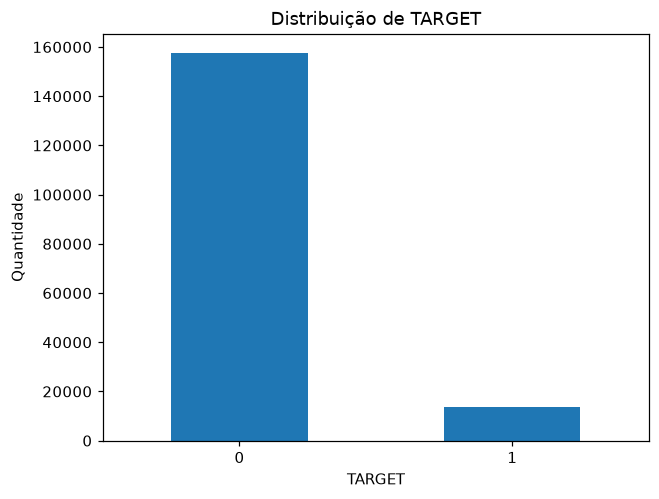

In [26]:
treino["TARGET"].value_counts().sort_index().plot.bar(rot=0)
plt.title("Distribuição de TARGET")
plt.xlabel("TARGET")
plt.ylabel("Quantidade")
plt.show()

Há 13.821 casos com TARGET=1, aproximadamente 8,07% do treino. Vamos preservar a proporção das classes ao separar treino e validação. Não aplicaremos balanceamento artificial de forma automática.

### 12. Examinar as categorias
describe(include=...) resume as colunas em texto. Depois vemos suas categorias e frequências. Observe valores como XNA e Unknown.

In [27]:
treino[categoricas].describe().T

,count,unique,top,freq
NAME_CONTRACT_TYPE,171202,2,Cash loans,154988
CODE_GENDER,171202,3,F,112549
NAME_INCOME_TYPE,171202,8,Working,88268
NAME_EDUCATION_TYPE,171202,5,Secondary / secondary special,121612
NAME_FAMILY_STATUS,171202,6,Married,109323
NAME_HOUSING_TYPE,171202,6,House / apartment,151916
OCCUPATION_TYPE,171202,19,Other,53745
ORGANIZATION_TYPE,171202,58,Business Entity Type 3,37943


In [28]:
for coluna in categoricas:
    print("\n", coluna)
    print(treino[coluna].value_counts(dropna=False))


 NAME_CONTRACT_TYPE
NAME_CONTRACT_TYPE
Cash loans         154988
Revolving loans     16214
Name: count, dtype: int64

 CODE_GENDER
CODE_GENDER
F      112549
M       58649
XNA         4
Name: count, dtype: int64

 NAME_INCOME_TYPE
NAME_INCOME_TYPE
Working                 88268
Commercial associate    40007
Pensioner               30895
State servant           12007
Unemployed                 10
Student                     9
Businessman                 3
Maternity leave             3
Name: count, dtype: int64

 NAME_EDUCATION_TYPE
NAME_EDUCATION_TYPE
Secondary / secondary special    121612
Higher education                  41645
Incomplete higher                  5711
Lower secondary                    2133
Academic degree                     101
Name: count, dtype: int64

 NAME_FAMILY_STATUS
NAME_FAMILY_STATUS
Married                 109323
Single / not married     25285
Civil marriage           16652
Separated                10988
Widow                     8952
Unknown                

Vamos comparar a taxa do alvo por nível de escolaridade como exemplo de exploração categórica. count mostra o tamanho do grupo e mean a taxa de TARGET=1. Uma taxa baseada em poucos casos deve ser interpretada com cuidado.

In [29]:
treino.groupby("NAME_EDUCATION_TYPE")["TARGET"].agg(["count", "mean"])

,count,mean
NAME_EDUCATION_TYPE,,
Academic degree,101,0.009901
Higher education,41645,0.053692
Incomplete higher,5711,0.087200
Lower secondary,2133,0.110642
Secondary / secondary special,121612,0.089218


### 13. Comparar treino e teste
Compare as medianas e as ausências. Também procure categorias que aparecem no teste e não no treino. Isso ajuda a antecipar problemas na preparação.

In [30]:
pd.DataFrame({
    "mediana_treino": treino[numericas].median(),
    "mediana_teste": teste[numericas].median(),
    "ausencia_treino_pct": treino[numericas].isna().mean() * 100,
    "ausencia_teste_pct": teste[numericas].isna().mean() * 100
})

,mediana_treino,mediana_teste,ausencia_treino_pct,ausencia_teste_pct
CNT_CHILDREN,0.000000,0.000000,0.000000,0.000000
AMT_INCOME_TOTAL,146250.000000,144000.000000,0.000000,0.000000
AMT_CREDIT,514602.000000,509400.000000,0.000000,0.000000
AMT_ANNUITY,24916.500000,24849.000000,0.000000,0.000000
AMT_GOODS_PRICE,450000.000000,450000.000000,0.000000,0.000000
REGION_POPULATION_RELATIVE,0.018850,0.018850,0.000000,0.000000
DAYS_BIRTH,-15778.000000,-15586.500000,0.000000,0.000000
DAYS_EMPLOYED,-1215.000000,-1185.000000,0.000000,0.000000
DAYS_REGISTRATION,-4515.000000,-4458.000000,0.000000,0.000000
DAYS_ID_PUBLISH,-3247.000000,-3218.000000,0.000000,0.000000


In [31]:
for coluna in categoricas:
    novas = teste.loc[
        teste[coluna].notna() & ~teste[coluna].isin(treino[coluna]),
        coluna
    ].unique()
    print(coluna, "— categorias novas:", novas)

NAME_CONTRACT_TYPE — categorias novas: <ArrowStringArray>
[]
Length: 0, dtype: str
CODE_GENDER — categorias novas: <ArrowStringArray>
[]
Length: 0, dtype: str
NAME_INCOME_TYPE — categorias novas: <ArrowStringArray>
[]
Length: 0, dtype: str
NAME_EDUCATION_TYPE — categorias novas: <ArrowStringArray>
[]
Length: 0, dtype: str
NAME_FAMILY_STATUS — categorias novas: <ArrowStringArray>
[]
Length: 0, dtype: str
NAME_HOUSING_TYPE — categorias novas: <ArrowStringArray>
[]
Length: 0, dtype: str
OCCUPATION_TYPE — categorias novas: <ArrowStringArray>
[]
Length: 0, dtype: str
ORGANIZATION_TYPE — categorias novas: <ArrowStringArray>
[]
Length: 0, dtype: str


### 14. Encerrar a primeira exploração
Até aqui, **nenhuma célula alterou treino ou teste**. Observamos as bases antes de decidir o tratamento.

As decisões desta primeira versão são:

| O que observamos | Decisão |
| --- | --- |
| Sentinela 365243 em DAYS_EMPLOYED | Converter em ausência |
| Marcadores XNA, XAP, Unknown ou texto vazio | Representar como ausência |
| Carro com 60 anos ou mais | Aplicar a hipótese do tutorial e documentá-la |
| Rendas muito altas | Preservar; não temos confirmação de erro |
| Muitas lacunas em algumas colunas | Manter as colunas e criar indicadores de ausência |
| Ausências numéricas | Preencher com medianas aprendidas no subtreino |
| Categorias em texto | Preencher com Ausente e fazer one-hot |
| Alvo desbalanceado | Fazer divisão estratificada e usar ROC-AUC futuramente |
| ID de linha | Guardar para identificação e retirar das entradas do modelo |

A exploração do alvo usou todo o treino rotulado. A validação posterior será exploratória se essas observações guiarem escolhas de variáveis ou parâmetros.

## Parte 2 — Tratar os dados
### 15. Criar cópias
Agora começa o tratamento. As alterações serão feitas em cópias, preservando treino e teste como foram carregados.

In [32]:
treino_limpo = treino.copy()
teste_limpo = teste.copy()

### 16. Tratar a sentinela de emprego
Transformamos apenas o valor identificado na exploração. Os dias negativos continuam com o mesmo significado.

In [33]:
treino_limpo["DAYS_EMPLOYED"] = treino_limpo["DAYS_EMPLOYED"].replace(365243, np.nan)
teste_limpo["DAYS_EMPLOYED"] = teste_limpo["DAYS_EMPLOYED"].replace(365243, np.nan)

### 17. Aplicar a regra do tutorial para idade do carro
Nesta versão, idades a partir de 60 viram ausência. Para estudar a sensibilidade a essa escolha, podemos depois refazer a comparação preservando os valores. Não alteramos o alvo.

In [34]:
treino_limpo.loc[treino_limpo["OWN_CAR_AGE"] >= 60, "OWN_CAR_AGE"] = np.nan
teste_limpo.loc[teste_limpo["OWN_CAR_AGE"] >= 60, "OWN_CAR_AGE"] = np.nan

### 18. Organizar os textos e marcadores
Retiramos espaços nas bordas e padronizamos os marcadores de desconhecido. XNA em ORGANIZATION_TYPE também pode indicar uma situação estrutural de trabalho; ao virar Ausente na codificação, essa condição continua representada como uma categoria.

In [35]:
for coluna in categoricas:
    treino_limpo[coluna] = treino_limpo[coluna].str.strip()
    teste_limpo[coluna] = teste_limpo[coluna].str.strip()

marcadores = {"": np.nan, "XNA": np.nan, "XAP": np.nan, "Unknown": np.nan}
treino_limpo[categoricas] = treino_limpo[categoricas].replace(marcadores)
teste_limpo[categoricas] = teste_limpo[categoricas].replace(marcadores)

### 19. Conferir o que mudou
Verificamos as ausências antes e depois. O aumento é esperado quando uma sentinela passa a ser representada corretamente como ausência.

In [36]:
pd.DataFrame({
    "antes": treino.isna().sum(),
    "depois": treino_limpo.isna().sum()
}).query("antes != depois")

,antes,depois
CODE_GENDER,0,4
NAME_FAMILY_STATUS,0,2
DAYS_EMPLOYED,0,30898
OWN_CAR_AGE,112992,114818
ORGANIZATION_TYPE,0,30898


In [37]:
print("Mesmo número de linhas:", len(treino_limpo) == len(treino))
print("IDs preservados:", treino_limpo["SK_ID_CURR"].equals(treino["SK_ID_CURR"]))
print("TARGET preservado:", treino_limpo["TARGET"].equals(treino["TARGET"]))
print("Sentinelas restantes:", treino_limpo["DAYS_EMPLOYED"].eq(365243).sum())

Mesmo número de linhas: True
IDs preservados: True
TARGET preservado: True
Sentinelas restantes: 0


Vamos rever as associações com o alvo depois da limpeza. Usaremos Spearman, que compara a ordem dos valores e pode ajudar em distribuições assimétricas. Os resultados não são diretamente comparáveis à primeira matriz de Pearson, pois mudaram tanto o tratamento quanto a medida.

In [38]:
correlacao_limpa = treino_limpo.drop(columns="SK_ID_CURR").corr(
    numeric_only=True, method="spearman"
)
correlacao_limpa["TARGET"].drop("TARGET").sort_values()

EXT_SOURCE_3                 -0.165889
EXT_SOURCE_1                 -0.150163
EXT_SOURCE_2                 -0.149300
AMT_GOODS_PRICE              -0.033886
REGION_POPULATION_RELATIVE   -0.033056
AMT_CREDIT                   -0.020027
AMT_INCOME_TOTAL             -0.017187
AMT_REQ_CREDIT_BUREAU_QRT    -0.009506
AMT_REQ_CREDIT_BUREAU_MON    -0.008615
AMT_ANNUITY                  -0.002208
FLAG_MOBIL                    0.000716
AMT_REQ_CREDIT_BUREAU_HOUR    0.000970
CNT_FAM_MEMBERS               0.006403
AMT_REQ_CREDIT_BUREAU_YEAR    0.019382
CNT_CHILDREN                  0.019624
FLAG_WORK_PHONE               0.029102
DAYS_REGISTRATION             0.040245
FLAG_EMP_PHONE                0.045646
DAYS_LAST_PHONE_CHANGE        0.053387
OWN_CAR_AGE                   0.053457
DAYS_ID_PUBLISH               0.053583
REGION_RATING_CLIENT          0.058942
DAYS_EMPLOYED                 0.078647
DAYS_BIRTH                    0.079626
Name: TARGET, dtype: float64

### 20. Salvar a base limpa comum
Esta base mantém as 32 variáveis originais, o ID e, no treino, o TARGET. Ela ainda contém ausências. Essa é uma escolha intencional: cada divisão futura deve aprender seu próprio preenchimento a partir da parte de treinamento.

Os próximos notebooks podem partir daqui para comparar modelos usando o mesmo processo.

In [39]:
(pasta / "dados_tratados").mkdir(exist_ok=True)

treino_limpo.to_csv(pasta / "dados_tratados" / "train.csv", index=False)
teste_limpo.to_csv(pasta / "dados_tratados" / "test.csv", index=False)

## Parte 3 — Preparar uma divisão comum para os próximos modelos
### 21. Separar entradas, alvo e validação
Vamos usar 80% das linhas rotuladas para treinamento e 20% para validação, com test_size=0.20. O teste fornecido pelo curso permanece separado. A semente fixa permite reproduzir o resultado. stratify preserva a proporção das classes.

Faremos o preenchimento e a codificação depois da divisão. A validação e o teste não poderão influenciar as medianas ou as categorias aprendidas.

In [40]:
from sklearn.model_selection import train_test_split

X = treino_limpo.drop(columns=["SK_ID_CURR", "TARGET"])
y = treino_limpo["TARGET"]
X_teste = teste_limpo.drop(columns="SK_ID_CURR").copy()

X_treino, X_validacao, y_treino, y_validacao = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
X_treino = X_treino.copy()
X_validacao = X_validacao.copy()

print("Treino:", X_treino.shape)
print("Validação:", X_validacao.shape)
print("Teste:", X_teste.shape)

Treino: (136961, 32)
Validação: (34241, 32)
Teste: (61500, 32)


### 22. Criar indicadores de ausência
Para cada variável numérica, criamos uma coluna que vale 1 quando a informação falta. Isso permite manter o sinal de ausência mesmo depois de preencher o valor.

In [41]:
for coluna in numericas:
    X_treino[coluna + "_AUSENTE"] = X_treino[coluna].isna().astype(int)
    X_validacao[coluna + "_AUSENTE"] = X_validacao[coluna].isna().astype(int)
    X_teste[coluna + "_AUSENTE"] = X_teste[coluna].isna().astype(int)

### 23. Preencher ausências numéricas
Calculamos a mediana somente em X_treino e usamos os mesmos valores nas três bases. A mediana é um ponto de partida simples e menos sensível a extremos que a média.

Se uma coluna estivesse inteiramente vazia no subtreino, seria necessário escolher um tratamento específico. Vamos verificar isso antes.

In [42]:
X_treino[numericas].isna().all()

CNT_CHILDREN                  False
AMT_INCOME_TOTAL              False
AMT_CREDIT                    False
AMT_ANNUITY                   False
AMT_GOODS_PRICE               False
REGION_POPULATION_RELATIVE    False
DAYS_BIRTH                    False
DAYS_EMPLOYED                 False
DAYS_REGISTRATION             False
DAYS_ID_PUBLISH               False
OWN_CAR_AGE                   False
FLAG_MOBIL                    False
FLAG_EMP_PHONE                False
FLAG_WORK_PHONE               False
CNT_FAM_MEMBERS               False
REGION_RATING_CLIENT          False
EXT_SOURCE_1                  False
EXT_SOURCE_2                  False
EXT_SOURCE_3                  False
DAYS_LAST_PHONE_CHANGE        False
AMT_REQ_CREDIT_BUREAU_HOUR    False
AMT_REQ_CREDIT_BUREAU_MON     False
AMT_REQ_CREDIT_BUREAU_QRT     False
AMT_REQ_CREDIT_BUREAU_YEAR    False
dtype: bool

In [43]:
medianas = X_treino[numericas].median()
medianas

CNT_CHILDREN                       0.000000
AMT_INCOME_TOTAL              144000.000000
AMT_CREDIT                    513531.000000
AMT_ANNUITY                    24916.500000
AMT_GOODS_PRICE               450000.000000
REGION_POPULATION_RELATIVE         0.018850
DAYS_BIRTH                    -15779.000000
DAYS_EMPLOYED                  -1648.000000
DAYS_REGISTRATION              -4522.000000
DAYS_ID_PUBLISH                -3251.000000
OWN_CAR_AGE                        9.000000
FLAG_MOBIL                         1.000000
FLAG_EMP_PHONE                     1.000000
FLAG_WORK_PHONE                    0.000000
CNT_FAM_MEMBERS                    2.000000
REGION_RATING_CLIENT               2.000000
EXT_SOURCE_1                       0.505190
EXT_SOURCE_2                       0.565983
EXT_SOURCE_3                       0.535276
DAYS_LAST_PHONE_CHANGE          -758.000000
AMT_REQ_CREDIT_BUREAU_HOUR         0.000000
AMT_REQ_CREDIT_BUREAU_MON          0.000000
AMT_REQ_CREDIT_BUREAU_QRT       

In [44]:
X_treino[numericas] = X_treino[numericas].fillna(medianas)
X_validacao[numericas] = X_validacao[numericas].fillna(medianas)
X_teste[numericas] = X_teste[numericas].fillna(medianas)

### 24. Preencher textos e transformar categorias
Primeiro representamos texto ausente pela categoria Ausente. Depois, get_dummies cria colunas de 0/1. Por exemplo, cada tipo de contrato passa a ter sua própria coluna.

In [45]:
X_treino[categoricas] = X_treino[categoricas].fillna("Ausente")
X_validacao[categoricas] = X_validacao[categoricas].fillna("Ausente")
X_teste[categoricas] = X_teste[categoricas].fillna("Ausente")

In [46]:
X_treino = pd.get_dummies(X_treino, columns=categoricas, dtype=int)
X_validacao = pd.get_dummies(X_validacao, columns=categoricas, dtype=int)
X_teste = pd.get_dummies(X_teste, columns=categoricas, dtype=int)

### 25. Alinhar as colunas
Os modelos precisam receber as mesmas colunas na mesma ordem. Usamos as colunas do subtreino como referência. Categorias que aparecem apenas na validação ou no teste ficam sem uma coluna própria, uma limitação simples desta estratégia.

In [47]:
X_validacao = X_validacao.reindex(columns=X_treino.columns, fill_value=0)
X_teste = X_teste.reindex(columns=X_treino.columns, fill_value=0)

### 26. Retirar colunas constantes no subtreino
Uma coluna com um único valor não ajuda a diferenciar as linhas nessa amostra. Vamos mostrar os nomes antes de retirar as mesmas colunas das três bases.

In [48]:
constantes = X_treino.columns[X_treino.nunique() <= 1].tolist()
constantes

['CNT_CHILDREN_AUSENTE', 'AMT_INCOME_TOTAL_AUSENTE', 'AMT_CREDIT_AUSENTE', 'AMT_ANNUITY_AUSENTE', 'AMT_GOODS_PRICE_AUSENTE', 'REGION_POPULATION_RELATIVE_AUSENTE', 'DAYS_BIRTH_AUSENTE', 'DAYS_REGISTRATION_AUSENTE', 'DAYS_ID_PUBLISH_AUSENTE', 'FLAG_MOBIL_AUSENTE', 'FLAG_EMP_PHONE_AUSENTE', 'FLAG_WORK_PHONE_AUSENTE', 'REGION_RATING_CLIENT_AUSENTE', 'DAYS_LAST_PHONE_CHANGE_AUSENTE']

In [49]:
X_treino = X_treino.drop(columns=constantes)
X_validacao = X_validacao.drop(columns=constantes)
X_teste = X_teste.drop(columns=constantes)

### 27. Conferir a preparação
Queremos as mesmas colunas, nenhuma ausência e nenhum infinito. ID e TARGET devem estar fora das entradas.

In [50]:
print("Ausências no treino:", X_treino.isna().sum().sum())
print("Ausências na validação:", X_validacao.isna().sum().sum())
print("Ausências no teste:", X_teste.isna().sum().sum())
print("Mesmas colunas:", X_treino.columns.equals(X_validacao.columns)
      and X_treino.columns.equals(X_teste.columns))
print("Infinitos no treino:", np.isinf(X_treino).sum().sum())
print("Infinitos na validação:", np.isinf(X_validacao).sum().sum())
print("Infinitos no teste:", np.isinf(X_teste).sum().sum())

Ausências no treino: 0
Ausências na validação: 0
Ausências no teste: 0
Mesmas colunas: True
Infinitos no treino: 0
Infinitos na validação: 0
Infinitos no teste: 0


In [51]:
X_treino.head()

,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,DAYS_EMPLOYED_AUSENTE,OWN_CAR_AGE_AUSENTE,CNT_FAM_MEMBERS_AUSENTE,EXT_SOURCE_1_AUSENTE,EXT_SOURCE_2_AUSENTE,EXT_SOURCE_3_AUSENTE,AMT_REQ_CREDIT_BUREAU_HOUR_AUSENTE,AMT_REQ_CREDIT_BUREAU_MON_AUSENTE,AMT_REQ_CREDIT_BUREAU_QRT_AUSENTE,AMT_REQ_CREDIT_BUREAU_YEAR_AUSENTE,NAME_CONTRACT_TYPE_Cash loans,NAME_CONTRACT_TYPE_Revolving loans,CODE_GENDER_Ausente,CODE_GENDER_F,CODE_GENDER_M,NAME_INCOME_TYPE_Businessman,...,ORGANIZATION_TYPE_Industry: type 12,ORGANIZATION_TYPE_Industry: type 13,ORGANIZATION_TYPE_Industry: type 2,ORGANIZATION_TYPE_Industry: type 3,ORGANIZATION_TYPE_Industry: type 4,ORGANIZATION_TYPE_Industry: type 5,ORGANIZATION_TYPE_Industry: type 6,ORGANIZATION_TYPE_Industry: type 7,ORGANIZATION_TYPE_Industry: type 8,ORGANIZATION_TYPE_Industry: type 9,ORGANIZATION_TYPE_Insurance,ORGANIZATION_TYPE_Kindergarten,ORGANIZATION_TYPE_Legal Services,ORGANIZATION_TYPE_Medicine,ORGANIZATION_TYPE_Military,ORGANIZATION_TYPE_Mobile,ORGANIZATION_TYPE_Other,ORGANIZATION_TYPE_Police,ORGANIZATION_TYPE_Postal,ORGANIZATION_TYPE_Realtor,ORGANIZATION_TYPE_Religion,ORGANIZATION_TYPE_Restaurant,ORGANIZATION_TYPE_School,ORGANIZATION_TYPE_Security,ORGANIZATION_TYPE_Security Ministries,ORGANIZATION_TYPE_Self-employed,ORGANIZATION_TYPE_Services,ORGANIZATION_TYPE_Telecom,ORGANIZATION_TYPE_Trade: type 1,ORGANIZATION_TYPE_Trade: type 2,ORGANIZATION_TYPE_Trade: type 3,ORGANIZATION_TYPE_Trade: type 4,ORGANIZATION_TYPE_Trade: type 5,ORGANIZATION_TYPE_Trade: type 6,ORGANIZATION_TYPE_Trade: type 7,ORGANIZATION_TYPE_Transport: type 1,ORGANIZATION_TYPE_Transport: type 2,ORGANIZATION_TYPE_Transport: type 3,ORGANIZATION_TYPE_Transport: type 4,ORGANIZATION_TYPE_University
35874,1,225000.0,288873.0,17329.5,238500.0,0.020713,-9072,-1708.0,-8175.0,-1713,19.0,1,1,0,3.0,3,0.505190,0.000654,0.130129,-1.0,0.0,0.0,0.0,8.0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
133776,0,225000.0,668304.0,26631.0,540000.0,0.016612,-20978,-10770.0,-11322.0,-3997,9.0,1,1,0,1.0,2,0.505190,0.470215,0.549597,-447.0,0.0,0.0,0.0,2.0,0,1,0,1,0,0,0,0,0,0,1,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
87618,0,90000.0,254700.0,24939.0,225000.0,0.010147,-24612,-1648.0,-6850.0,-4457,9.0,1,0,0,2.0,2,0.505190,0.734209,0.661024,-689.0,0.0,0.0,0.0,0.0,1,1,0,1,0,0,0,0,0,0,1,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4496,0,157500.0,450000.0,30573.0,450000.0,0.030755,-8990,-628.0,-3634.0,-655,2.0,1,1,0,1.0,2,0.505190,0.590657,0.073473,0.0,0.0,0.0,0.0,1.0,0,0,0,1,0,0,0,0,0,0,1,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
27581,2,81000.0,225000.0,11250.0,225000.0,0.015221,-14261,-422.0,-395.0,-77,9.0,1,1,0,4.0,2,0.192925,0.388086,0.535276,0.0,0.0,0.0,0.0,1.0,0,1,0,0,0,1,1,1,1,1,0,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0


### 28. Salvar a divisão que será compartilhada entre os modelos
Guardamos também o ID e o alvo para recuperar a associação entre linhas. Nos notebooks de previsão, retire ID e TARGET das entradas novamente.

Todos os modelos de uma comparação devem usar esta mesma divisão. Para outra semente ou validação cruzada, volte à base limpa e refaça o preenchimento e a codificação dentro de cada partição.

In [52]:
treino_preparado = X_treino.copy()
treino_preparado.insert(0, "SK_ID_CURR", treino_limpo.loc[X_treino.index, "SK_ID_CURR"])
treino_preparado["TARGET"] = y_treino

validacao_preparada = X_validacao.copy()
validacao_preparada.insert(0, "SK_ID_CURR", treino_limpo.loc[X_validacao.index, "SK_ID_CURR"])
validacao_preparada["TARGET"] = y_validacao

teste_preparado = X_teste.copy()
teste_preparado.insert(0, "SK_ID_CURR", teste_limpo["SK_ID_CURR"])

In [53]:
(pasta / "dados_modelagem").mkdir(exist_ok=True)

treino_preparado.to_csv(pasta / "dados_modelagem" / "treino.csv", index=False)
validacao_preparada.to_csv(pasta / "dados_modelagem" / "validacao.csv", index=False)
teste_preparado.to_csv(pasta / "dados_modelagem" / "teste.csv", index=False)

print("Arquivos salvos em dados_tratados e dados_modelagem.")

Arquivos salvos em dados_tratados e dados_modelagem.


## Onde este notebook termina
A exploração e a preparação estão concluídas. Os próximos notebooks vão carregar a mesma base para treinar cada modelo, comparar ROC-AUC e então experimentar ensembles de dois em dois.

A base limpa é comum, mas alguns algoritmos exigem preparação adicional. Modelos baseados em distância ou gradientes podem precisar de escalonamento; árvores geralmente não. Qualquer transformação adicional deve ser ajustada somente na parte de treinamento.

**Para você registrar:** quais problemas encontrou, quais decisões tomou e qual hipótese gostaria de comparar na próxima versão.

Fontes: [dicionário do curso](https://docs.google.com/spreadsheets/d/15yVsSZCn2qtOfbBUrBDmCPaVacne0jnZ/edit), [tutorial](https://drive.google.com/file/d/12x-eLfkF39hctLMUqcalWRUnvrlcvCaD/view) e [regras da competição](https://drive.google.com/file/d/1ryBfQlw55rv2CsLXjLIb9BUwQKwzZQ06/view). Notebook elaborado com assistência de ChatGPT/Codex. Dados usados: somente os arquivos fornecidos pelo curso.